# 01. 탐색적 데이터 분석 (EDA)

> README **5. 데이터셋**, **6.1 탐색적 데이터 분석**에 대응하는 노트북입니다.

**목적**
모델링 전에 데이터 구조, Target 불균형 정도, 데이터 품질, Feature 분포와 Feature–Target 관계를 확인하고, 이를 근거로 전처리(02)와 모델링(03) 방향을 정합니다.

**원칙**
- EDA는 **Train 데이터(1,552건)만** 사용합니다. Test 정보가 분석 판단에 섞이지 않도록 하기 위함입니다.
- 전처리 결정의 근거를 찾는 단계이므로 **원본 데이터(`data/raw/Faults.csv`)**를 사용합니다. 실제 전처리는 02에서 수행합니다.
- 분할 인덱스는 `src/make_split.py`로 만든 팀 공통 `data/split/train_idx.csv`를 사용합니다.

| 섹션 | 내용 |
|---|---|
| 1 | 데이터 불러오기 및 기본 구조 |
| 2 | Target 분포와 불균형 정도 |
| 3 | 데이터 품질 (결측·중복·값 범위·Target 구조·강종 변수) |
| 4 | Feature 분포 (왜도) |
| 5 | Feature 간 관계 (상관) |
| 6 | Feature–Target 관계 |
| 7 | Other_Faults 내부 특성 |
| 8 | EDA 결론 및 전처리·모델링 결정 |

In [1]:
import sys
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 노트북 위치와 무관하게 프로젝트 루트(src/config.py가 있는 폴더)를 찾는다
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# 한글 폰트: OS별로 있는 폰트를 순서대로 사용
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic",
                               "Noto Sans CJK KR", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.width", 200)

## 1. 데이터 불러오기 및 기본 구조

원본 데이터에서 Train 인덱스에 해당하는 행만 사용합니다. Target은 7개 원-핫 열 중 1인 열의 이름으로 만들고, 표기 통일을 위해 라벨명 `K_Scatch`만 `K_Scratch`로 바꿔 표시합니다.

In [2]:
from config import TARGET_COLS   # 원본 열 이름 기준 (K_Scatch 포함)

raw = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "Faults.csv")
train_idx = pd.read_csv(PROJECT_ROOT / "data" / "split" / "train_idx.csv")["index"]

X_train = raw.drop(columns=TARGET_COLS).loc[train_idx]
y_train = (raw[TARGET_COLS].idxmax(axis=1)
           .replace({"K_Scatch": "K_Scratch"})
           .loc[train_idx])

print("원본 전체:", raw.shape)
print("X_train  :", X_train.shape)
print("y_train  :", y_train.shape)
X_train.head()

원본 전체: (1941, 34)
X_train  : (1552, 27)
y_train  : (1552,)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
480,41,190,1799909,1800071,11388,705,420,1311391,36,140,...,0.1063,0.2113,0.3857,1.0000,4.0564,2.1732,2.2095,0.0803,-0.1003,1.0000
1190,896,904,801872,801889,65,12,17,7974,113,135,...,0.0059,0.6667,1.0000,1.0000,1.8129,0.9031,1.2305,0.5294,-0.0416,0.2482
866,38,49,735612,735624,113,11,12,12652,93,130,...,0.0064,1.0000,1.0000,1.0000,2.0531,1.0414,1.0792,0.0833,-0.1253,0.2432
431,41,215,1157189,1157378,16584,821,498,1936241,25,143,...,0.1245,0.2119,0.3795,1.0000,4.2197,2.2406,2.2765,0.0794,-0.0879,1.0000
434,39,212,1185602,1185752,13387,763,425,1546189,29,141,...,0.1238,0.2267,0.3529,0.0000,4.1267,2.2380,2.1761,-0.1329,-0.0977,1.0000


In [3]:
print("[데이터 타입]")
print(X_train.dtypes.value_counts().to_string())
X_train.describe().T

[데이터 타입]
int64      14
float64    13


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1552.0000,562.0509,515.2177,0.0000,52.7500,405.5000,1038.7500,1705.0000
X_Maximum,1552.0000,609.5696,492.2804,4.0000,192.7500,445.0000,1061.5000,1713.0000
Y_Minimum,1552.0000,1662716.6437,1811260.0185,6712.0000,462923.5000,1188619.0000,2182183.5000,12987661.0000
Y_Maximum,1552.0000,1662761.3499,1811258.4190,6724.0000,462947.2500,1188705.5000,2182200.2500,12987692.0000
Pixels_Areas,1552.0000,1870.0831,4007.8558,2.0000,85.0000,170.5000,822.5000,37334.0000
X_Perimeter,1552.0000,107.9929,192.1300,2.0000,15.0000,26.5000,83.2500,1275.0000
Y_Perimeter,1552.0000,74.5380,119.2024,1.0000,13.0000,25.0000,80.0000,903.0000
Sum_of_Luminosity,1552.0000,206718.6424,459112.7242,250.0000,9548.7500,19125.0000,83647.2500,3918209.0000
Minimum_of_Luminosity,1552.0000,84.5064,32.4565,0.0000,62.0000,90.0000,106.0000,203.0000
Maximum_of_Luminosity,1552.0000,130.1952,18.9798,37.0000,124.0000,127.0000,140.0000,253.0000


**확인 결과**
- Train은 1,552건, 입력 Feature 27개이며 모두 수치형(int 14, float 13)입니다. 범주형 인코딩은 필요하지 않습니다.
- `Y_Minimum`(최대 약 1,300만)과 `Edges_Index`(0~1)처럼 Feature 간 값의 범위 차이가 매우 큽니다. → Scale에 민감한 모델은 Scaling이 필요합니다.
- 면적·둘레·밝기 합계는 평균이 중앙값보다 훨씬 커서 치우친 분포가 예상됩니다. → 4장에서 확인합니다.

## 2. Target 분포와 불균형 정도

불균형을 "있다/없다"로만 판단하지 않고, 유형별 실제 건수와 비율을 함께 확인합니다.

In [4]:
target_summary = pd.DataFrame({
    "Count": y_train.value_counts(),
    "Ratio(%)": (y_train.value_counts(normalize=True) * 100).round(2),
})
display(target_summary)

cnt = target_summary["Count"]
print(f"최다 유형: {cnt.idxmax()} ({cnt.max()}건)")
print(f"최소 유형: {cnt.idxmin()} ({cnt.min()}건)")
print(f"최대/최소 비율: {cnt.max() / cnt.min():.2f}배")
print(f"상위 3개 유형 비중: {target_summary['Ratio(%)'].head(3).sum():.1f}%")

,Count,Ratio(%)
Other_Faults,538,34.6600
Bumps,321,20.6800
K_Scratch,313,20.1700
Z_Scratch,152,9.7900
Pastry,126,8.1200
Stains,58,3.7400
Dirtiness,44,2.8400


최다 유형: Other_Faults (538건)
최소 유형: Dirtiness (44건)
최대/최소 비율: 12.23배
상위 3개 유형 비중: 75.5%


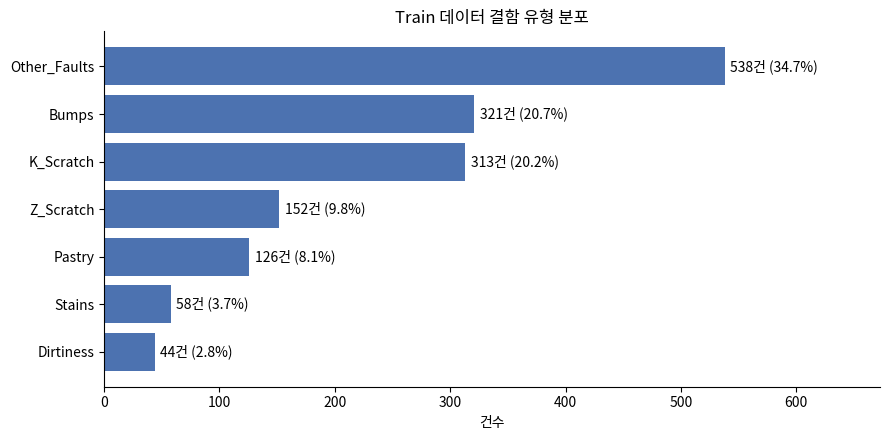

In [5]:
plot_df = target_summary.sort_values("Count")
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_df.index, plot_df["Count"], color="#4C72B0")
ax.bar_label(bars, labels=[f"{c}건 ({r:.1f}%)" for c, r in
                           zip(plot_df["Count"], plot_df["Ratio(%)"])], padding=4)
ax.set_xlim(0, plot_df["Count"].max() * 1.25)
ax.set_xlabel("건수")
ax.set_title("Train 데이터 결함 유형 분포")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**확인 결과**
- Other_Faults가 538건(34.66%)으로 가장 많고 Dirtiness가 44건(2.84%)으로 가장 적어 **최대/최소 12.23배** 차이가 있습니다.
- 상위 3개 유형(Other_Faults, Bumps, K_Scratch)이 Train의 약 75.5%를 차지합니다.

**판단**
- Accuracy는 다수 유형의 성능에 좌우되므로, **모든 유형의 F1을 같은 비중으로 평균하는 Macro F1**을 핵심 지표로 사용합니다.
- 단, "건수가 적은 유형 = 분류가 어려운 유형"이라고 미리 단정하지 않고, Baseline의 유형별 성능(03)으로 확인합니다.

## 3. 데이터 품질

각 항목을 **확인 → 처리 필요 여부 판단** 순서로 봅니다.

In [6]:
print("결측치 합계:", int(X_train.isna().sum().sum()))
print("중복 행 수 :", int(X_train.duplicated().sum()))

# Target 구조: 모든 행에서 원-핫 7개 열 중 정확히 1개만 1인가?
onehot_sum = raw.loc[train_idx, TARGET_COLS].sum(axis=1)
print("원-핫 합이 1이 아닌 행:", int((onehot_sum != 1).sum()))

결측치 합계: 0
중복 행 수 : 0
원-핫 합이 1이 아닌 행: 0


In [7]:
range_summary = pd.DataFrame({
    "min": X_train.min(),
    "max": X_train.max(),
    "n_unique": X_train.nunique(),
})
range_summary

,min,max,n_unique
X_Minimum,0.0000,1705.0000,844
X_Maximum,4.0000,1713.0000,870
Y_Minimum,6712.0000,12987661.0000,1552
Y_Maximum,6724.0000,12987692.0000,1552
Pixels_Areas,2.0000,37334.0000,787
X_Perimeter,2.0000,1275.0000,357
Y_Perimeter,1.0000,903.0000,288
Sum_of_Luminosity,250.0000,3918209.0000,1533
Minimum_of_Luminosity,0.0000,203.0000,152
Maximum_of_Luminosity,37.0000,253.0000,95


In [8]:
# 강종 변수 두 개가 같은 정보를 중복 표현하는지 확인
X_train[["TypeOfSteel_A300", "TypeOfSteel_A400"]].value_counts().sort_index()

TypeOfSteel_A300  TypeOfSteel_A400
0                 1                   931
1                 0                   621
Name: count, dtype: int64

**확인 결과**
- 결측치·중복 행은 0건입니다. → 처리하지 않습니다.
- 모든 행에서 원-핫 정답 열의 합이 1입니다. → 7개 열을 **단일 다중 분류 Target**으로 바꿀 수 있습니다. 이 정답 열들이 입력에 남으면 그대로 정답을 알려주는 **데이터 누수**가 되므로 반드시 제거합니다.
- 값의 범위에서 데이터 오류로 판단할 만한 값(음수 면적 등)은 보이지 않습니다.
- `TypeOfSteel_A300`과 `TypeOfSteel_A400`은 (0,1) 또는 (1,0)만 존재합니다. 두 열은 같은 정보를 반대로 표현하므로 **하나만 남겨도 정보 손실이 없습니다.**
- `Outside_Global_Index`는 고유값이 3개뿐인 이산형 지표입니다.

## 4. Feature 분포

왜도가 큰 Feature를 확인하고, 극단값이 데이터 오류인지 결함 특성인지 판단합니다.

In [9]:
skew = X_train.skew().sort_values(key=abs, ascending=False)
skew_df = skew.to_frame("skewness")
print("|왜도| ≥ 1 인 Feature")
skew_df[skew_df["skewness"].abs() >= 1]

|왜도| ≥ 1 인 Feature


,skewness
Outside_X_Index,5.2557
Sum_of_Luminosity,3.2465
Pixels_Areas,3.1066
X_Perimeter,2.8482
Y_Maximum,2.8097
Y_Minimum,2.8096
Y_Perimeter,2.8061
Steel_Plate_Thickness,2.2195
Maximum_of_Luminosity,1.2231


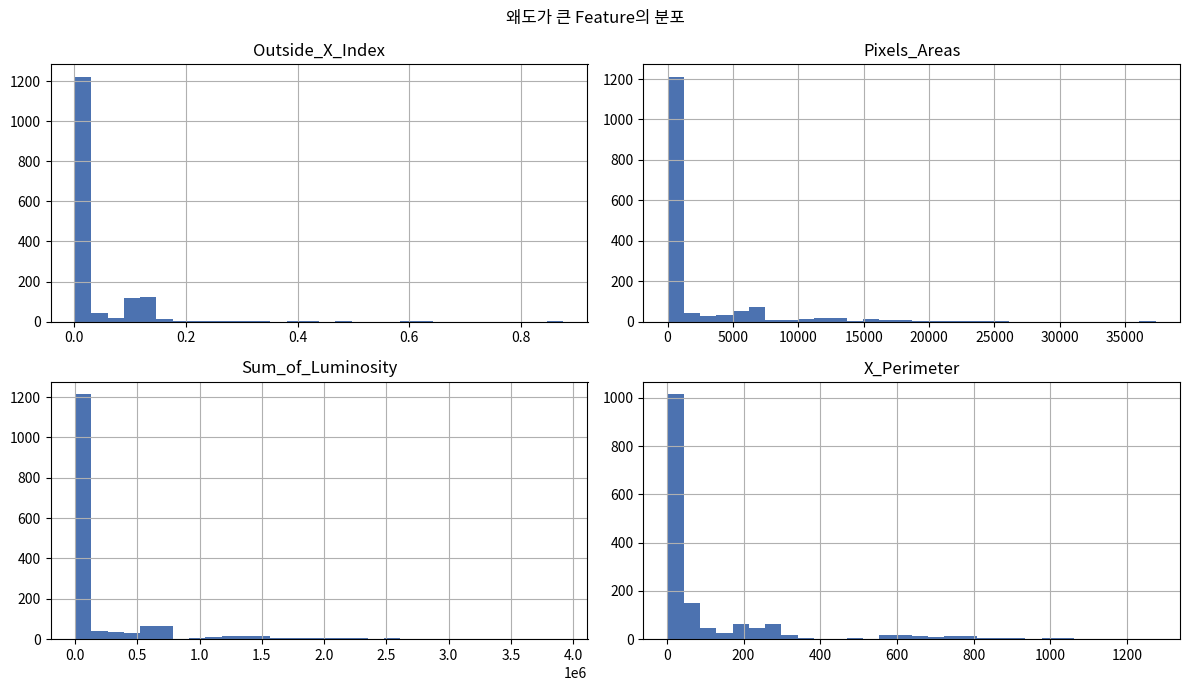

In [10]:
cols = ["Outside_X_Index", "Pixels_Areas", "Sum_of_Luminosity", "X_Perimeter"]
X_train[cols].hist(bins=30, figsize=(12, 7), color="#4C72B0")
plt.suptitle("왜도가 큰 Feature의 분포")
plt.tight_layout()
plt.show()

**확인 결과**
- `Outside_X_Index`(왜도 5.26), `Sum_of_Luminosity`(3.25), `Pixels_Areas`(3.11), `X_Perimeter`(2.85) 등에서 강한 오른쪽 꼬리가 확인됩니다. 대부분 작은 값에 몰려 있고 일부가 매우 큽니다.

**판단**
- 큰 값을 측정 오류로 볼 근거가 없고, 면적·둘레·밝기 합계가 함께 큰 것은 **큰 결함**이라는 자연스러운 특성일 가능성이 높습니다. → **극단값을 제거하지 않습니다.**
- 이미 `LogOfAreas`, `Log_X_Index` 등 로그 변환 Feature가 데이터에 포함되어 있습니다.

## 5. Feature 간 관계

정보가 중복되는 Feature 쌍을 확인합니다. 원본 크기 변수와 로그 변수처럼 **단조 관계**인 경우는 Pearson보다 Spearman이 중복을 더 잘 드러내므로 둘 다 봅니다.

In [11]:
corr = X_train.corr(method="pearson")
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ["Feature_1", "Feature_2", "Pearson"]
pairs = pairs.reindex(pairs["Pearson"].abs().sort_values(ascending=False).index)
pairs.head(15).reset_index(drop=True)

,Feature_1,Feature_2,Pearson
0,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000
1,Y_Minimum,Y_Maximum,1.0000
2,Pixels_Areas,Sum_of_Luminosity,0.9966
3,X_Minimum,X_Maximum,0.9875
4,X_Perimeter,Sum_of_Luminosity,0.9613
5,Pixels_Areas,X_Perimeter,0.9603
6,X_Perimeter,Y_Perimeter,0.9523
7,Y_Perimeter,Sum_of_Luminosity,0.9350
8,Pixels_Areas,Y_Perimeter,0.9334
9,LogOfAreas,Log_X_Index,0.8909


In [12]:
for a, b in [("Pixels_Areas", "LogOfAreas"), ("X_Minimum", "X_Maximum"),
             ("Y_Minimum", "Y_Maximum")]:
    print(f"{a:13s} ↔ {b:11s}  Pearson {X_train[a].corr(X_train[b]):.4f}"
          f" | Spearman {X_train[a].corr(X_train[b], method='spearman'):.4f}")

Pixels_Areas  ↔ LogOfAreas   Pearson 0.8015 | Spearman 1.0000
X_Minimum     ↔ X_Maximum    Pearson 0.9875 | Spearman 0.9461
Y_Minimum     ↔ Y_Maximum    Pearson 1.0000 | Spearman 1.0000


**확인 결과**
- `TypeOfSteel_A300`↔`A400`(−1.000), `Y_Minimum`↔`Y_Maximum`(1.000), `Pixels_Areas`↔`Sum_of_Luminosity`(0.997) 등 위치·크기 계열에서 매우 높은 상관이 있습니다.
- `Pixels_Areas`↔`LogOfAreas`는 Pearson 0.80이지만 Spearman 1.00입니다. 로그 변환으로 선형 관계는 약해졌지만 **값의 순서는 완전히 같습니다.**

**판단**
- 강종 변수는 완전 중복이므로 하나를 제거합니다(02).
- 그 외 상관이 높은 Feature는 트리 기반 모델에서 큰 문제가 되지 않고, EDA만으로 제거할 근거가 부족하므로 **유지**합니다. 다만 상관이 높은 Feature끼리는 Feature Importance가 나뉘어 보일 수 있다는 점을 해석 시 고려합니다.

## 6. Feature–Target 관계

**질문:** 결함 유형마다 Feature 분포가 다른가? 하나의 Feature로 모든 유형을 구분할 수 있는가?

먼저 Kruskal-Wallis 검정(정규분포 가정이 필요 없는 다집단 비교)으로 유형 간 분포 차이의 크기를 확인하고, 상위 Feature를 시각화합니다.

In [13]:
from scipy.stats import kruskal

kw = []
for col in X_train.columns:
    groups = [X_train.loc[y_train == c, col] for c in y_train.unique()]
    h, p = kruskal(*groups)
    kw.append({"Feature": col, "Kruskal_H": h, "p_value": p})

kw = pd.DataFrame(kw).sort_values("Kruskal_H", ascending=False).reset_index(drop=True)
print("p < 0.001 인 Feature 수:", int((kw["p_value"] < 0.001).sum()), "/", len(kw))
kw.head(10)

p < 0.001 인 Feature 수: 27 / 27


,Feature,Kruskal_H,p_value
0,Sum_of_Luminosity,656.8392,0.0000
1,Outside_X_Index,647.5910,0.0000
2,Log_X_Index,637.8982,0.0000
3,LogOfAreas,625.8363,0.0000
4,Pixels_Areas,625.8363,0.0000
5,Y_Perimeter,588.5976,0.0000
6,X_Perimeter,584.7961,0.0000
7,Edges_Y_Index,567.4138,0.0000
8,SigmoidOfAreas,564.0784,0.0000
9,Log_Y_Index,540.4094,0.0000


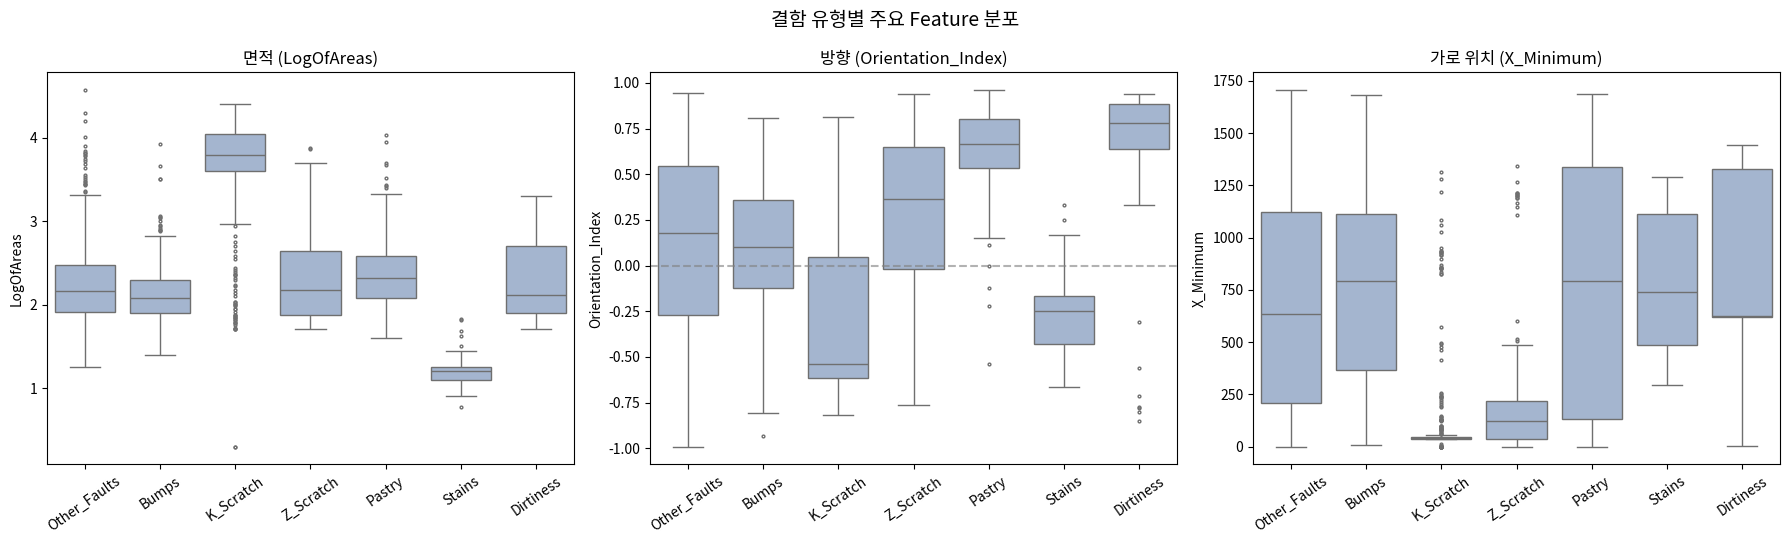

In [14]:
import seaborn as sns

eda = X_train.assign(Fault_Type=y_train.values)
order = y_train.value_counts().index

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, col, title in zip(
        axes,
        ["LogOfAreas", "Orientation_Index", "X_Minimum"],
        ["면적 (LogOfAreas)", "방향 (Orientation_Index)", "가로 위치 (X_Minimum)"]):
    sns.boxplot(data=eda, x="Fault_Type", y=col, order=order, ax=ax,
                color="#9DB4D6", fliersize=2)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
axes[1].axhline(0, ls="--", c="gray", alpha=0.6)

plt.suptitle("결함 유형별 주요 Feature 분포", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
steel = (pd.crosstab(eda["Fault_Type"], eda["TypeOfSteel_A300"], normalize="index") * 100)
steel.columns = ["A400(%)", "A300(%)"]
steel.round(1)

,A400(%),A300(%)
Fault_Type,,
Bumps,30.8000,69.2000
Dirtiness,79.5000,20.5000
K_Scratch,100.0000,0.0000
Other_Faults,60.2000,39.8000
Pastry,69.0000,31.0000
Stains,100.0000,0.0000
Z_Scratch,9.9000,90.1000


**확인 결과**
- 27개 Feature 모두 유형 간 분포 차이가 통계적으로 유의했습니다(p < 0.001). 다만 표본이 많으면 작은 차이도 유의하게 나오므로, **차이의 모양**을 그래프로 함께 확인했습니다.
- **면적:** K_Scratch는 다른 유형보다 크고 Stains는 매우 작습니다. 나머지 유형은 상당 부분 겹칩니다.
- **방향:** Pastry·Dirtiness는 양수 쪽, K_Scratch·Stains는 음수 쪽에 몰려 있습니다. 면적에서 겹치던 유형 일부가 방향에서는 구분됩니다.
- **위치:** K_Scratch는 매우 낮은 X 위치(강판 한쪽 가장자리)에 집중됩니다.
- **강종:** K_Scratch·Stains는 100% A400, Z_Scratch는 약 90%가 A300입니다.

**판단**
- Feature마다 구분해주는 유형이 다르므로, **여러 Feature를 함께 조합하는 비선형 모델**(트리 기반)이 유리할 것으로 예상합니다.
- 강종 정보는 Target과 연관이 뚜렷하므로 정보 자체는 유지합니다.
- Bumps·Other_Faults·Pastry는 여러 Feature에서 분포가 겹쳐 **서로 혼동될 가능성**이 있습니다. → Baseline 혼동행렬에서 확인합니다.

## 7. Other_Faults 내부 특성

Other_Faults는 가장 많은 유형이면서 "기타"라는 성격상 서로 다른 결함이 섞여 있을 수 있습니다.
**질문:** Other_Faults는 다른 유형보다 Feature 값이 넓게 퍼져 있는가?

각 유형의 Feature별 IQR(사분위 범위)을 전체 Train IQR로 나눈 **상대 IQR**로 비교합니다. 1에 가까울수록 그 유형 하나가 전체만큼 넓게 퍼져 있다는 뜻입니다.

In [16]:
total_iqr = X_train.quantile(0.75) - X_train.quantile(0.25)
rel_iqr = pd.DataFrame({
    c: (X_train[y_train == c].quantile(0.75) - X_train[y_train == c].quantile(0.25)) / total_iqr
    for c in y_train.unique()
}).replace([np.inf, -np.inf], np.nan)

rel_iqr.median().sort_values(ascending=False).to_frame("상대 IQR 중앙값")

,상대 IQR 중앙값
Other_Faults,0.9816
K_Scratch,0.7352
Pastry,0.7167
Dirtiness,0.6487
Bumps,0.6219
Z_Scratch,0.5858
Stains,0.2241


In [17]:
compare = pd.DataFrame({
    "Other_Faults": rel_iqr["Other_Faults"],
    "나머지 유형 중앙값": rel_iqr.drop(columns="Other_Faults").median(axis=1),
})
compare["배수"] = compare["Other_Faults"] / compare["나머지 유형 중앙값"]
compare.replace([np.inf], np.nan).dropna().sort_values("배수", ascending=False).head(8)

,Other_Faults,나머지 유형 중앙값,배수
Length_of_Conveyer,1.1190,0.0865,12.9406
Steel_Plate_Thickness,2.4937,0.2500,9.9750
Outside_Global_Index,1.0000,0.3125,3.2000
Edges_Y_Index,0.7136,0.2449,2.9140
Orientation_Index,0.9816,0.4501,2.1807
Minimum_of_Luminosity,0.6989,0.3750,1.8636
Outside_X_Index,0.5853,0.3353,1.7456
Luminosity_Index,1.3055,0.7789,1.6761


**확인 결과**
- Other_Faults의 상대 IQR 중앙값은 0.98로 7개 유형 중 가장 큽니다.
- 특히 `Length_of_Conveyer`, `Steel_Plate_Thickness` 등 공정 관련 Feature에서 다른 유형보다 훨씬 넓게 퍼져 있습니다. 반면 `Pixels_Areas` 등 크기 Feature에서는 그렇지 않습니다.

**해석 (가설)**
- Other_Faults는 여러 공정 조건에서 발생한 다양한 결함을 포함할 **가능성**이 있습니다.
- 다만 이 결과만으로 내부에 별도 하위 유형이 있다고 판단할 수는 없으므로 클래스를 나누지는 않습니다.

## 8. EDA 결론 및 전처리·모델링 결정

| 구분 | 내용 |
|---|---|
| **확인된 사실** | 결측·중복 0건 / 원-핫 합 = 1 / 강종 2개 열 완전 중복 / 크기·밝기 Feature 강한 우측 왜도 / 위치·크기 계열 높은 상관 / 최대·최소 유형 12.23배 차이 |
| **해석** | 극단값은 큰 결함의 특성일 가능성 / 단일 Feature로는 일부 유형만 구분됨 / Bumps·Other_Faults·Pastry는 분포가 겹침 |
| **가설 (추가 검증 필요)** | Other_Faults 내부 이질성 / 공정 Feature와 유형의 강한 연관이 모델 평가에 영향을 줄 가능성 |

**02 전처리로 넘기는 결정**
1. 원-핫 7개 열 → 단일 `target` 생성 후 원-핫 열 제거 (누수 방지)
2. `K_Scatch` → `K_Scratch` 표기 수정
3. `TypeOfSteel_A400` 제거 (`A300` 하나로 동일 정보 표현)
4. 결측·중복·극단값 처리 없음

**03 모델링으로 넘기는 결정**
- 핵심 지표: **Macro F1** (+ 유형별 Precision·Recall·F1, 혼동행렬)
- Scaling은 Logistic Regression에만, Pipeline 안에서 적용
- Bumps·Pastry·Other_Faults 간 혼동을 Baseline에서 중점 확인